In [12]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

In [13]:
# 도미
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [14]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight
data = [[l,w] for l,w in zip(length,weight)]
label = [1]*35 + [0]*14
len(length)



49

In [15]:
data[0:2]
# 데이터 전처리 
# 산술펼균
# 표준점수 : (특성값 - 산숭평균) / 표준편차
mean = np.mean(data,axis=0) # 행의 기준으로 산술평균
std = np.std(data,axis=0) # 행의 기준으로 표준편차
train_scaled = (data-mean)/std
new_data = ([25,120]-mean)/std
new_data2 = ([29.5,300]-mean)/std
new_data

array([-0.20271784, -0.99914535])

In [16]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,stratify=label)
len(train_data)

36

In [17]:
# 데이터 훈련
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)

# 데이터 예측
result = clf.predict(test_data)

# 정답률
score = clf.score(test_data,test_label)
score

1.0

[29.5, 330] 품종:빙어


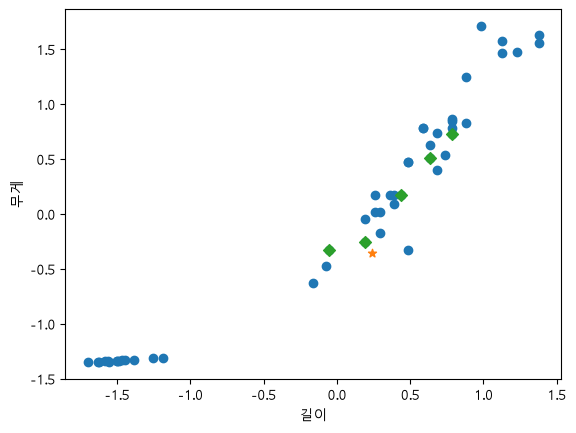

[25, 150] 품종:빙어


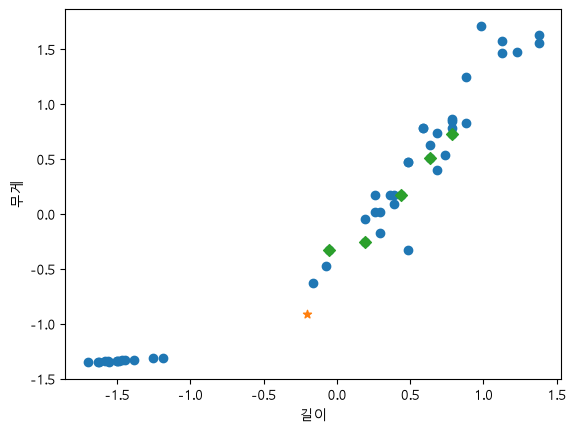

In [23]:
for t in [[29.5, 330], [25, 150]]:
    t_scaled = (np.array(t) - mean) / std                  # 스케일링
    result = clf.predict([t_scaled])
    print(t, '품종:도미' if result == 1 else '품종:빙어')

    distances, indexes = clf.kneighbors([t_scaled])        # 가까운 이웃 5개
    plt.scatter(train_scaled[:,0], train_scaled[:,1])
    plt.scatter(t_scaled[0], t_scaled[1], marker='*')
    plt.scatter(train_scaled[indexes,0], train_scaled[indexes,1], marker='D')
    plt.xlabel('길이')
    plt.ylabel('무게')
    plt.show()                                             # 값마다 그래프 따로

In [19]:
distances,indexes = clf.kneighbors([new_data])

In [20]:
# 길이 29.5, 무게 330 고기를 분류하시오
# 예측고기 : 도미, 빙어
# 길이 25, 무게 150 고기를 분류하시오

[29.5, 330] 품종:도미
[25, 150] 품종:빙어


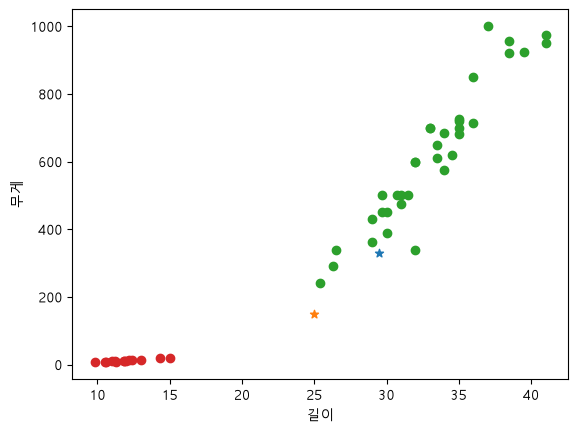

In [21]:


# data = input('length,weight')
# data2 = input('length,weight')

# data = [float(x) for x in data.split(',')]
# data2 = [float(x) for x in data2.split(',')]

# result = clf.predict([data])
# result1 = clf.predict([data2])

# if result ==1:
#     print('품종:도미')
# else:
#     print('품종:빙어')


# if result1 ==1:
#     print('품종:도미')
# else:
#     print('품종:빙어')
# # plt.scatter(bream_length,bream_weight)
# # plt.scatter(smelt_length,smelt_weight)
# # plt.scatter(data[0],data[1],marker='^')
# # plt.scatter(data2[0],data2[1],marker='^')
# # plt.xlabel('길이')
# # plt.ylabel('무게')
# # plt.show()


for t in [[29.5, 330], [25, 150]]:
    result = clf.predict([t])
    print(t, '품종:도미' if result == 1 else '품종:빙어')
    plt.scatter(t[0], t[1], marker='*')



plt.scatter(bream_length, bream_weight)
plt.scatter(smelt_length, smelt_weight)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()
